In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import gsw as gsw
import cartopy.crs as ccrs
import scipy

# Steps
1. open dataset
2. Check the latitudes
3. Calculate the f,xscale,yscale, 
4. Interpolate through the date line along the longitudes
5. We split the dataset into 2, one for lats and one for lons
6. We pad the two datasets (in their corresponding direction) for a couple grid cells, to ensure vanishing gradients at the boundaries
7. Differentiate in their respective directions and compute velocities
8. 

(101, 1440, 12)


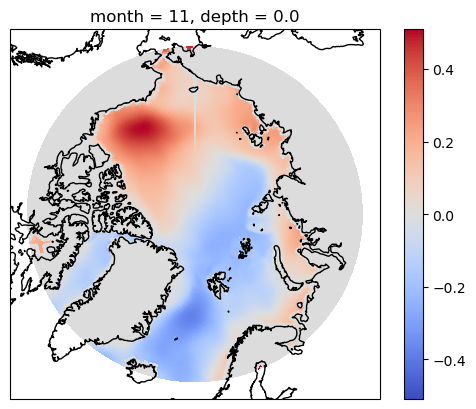

In [120]:
# 1. Open Dataset 
#    And readjust latitudes, and NaNs
ds = xr.open_dataset('../data/WOA_Bruno.nc')
ds.coords["lat"] = ds.coords["lat"].values[::-1] 

f= 2 * (2*np.pi/86400)*np.sin(ds["lat"]*(np.pi/180))
x_scale = 111000*np.cos(ds["lat"]*(np.pi/180))
y_scale=111000


T=ds['T'].isel({'depth':0,
                'month':0 
                })
SSH=xr.where(np.isnan(T),0,ds['W-ssh'])
land=xr.where(np.isnan(T),True,False)

# Visual sanity check 
fig,ax = plt.subplots(subplot_kw={'projection' : ccrs.NorthPolarStereo()})
SSH.isel({'month':10}).plot(cmap='coolwarm',transform=ccrs.PlateCarree())
print(SSH.shape)
ax.coastlines()


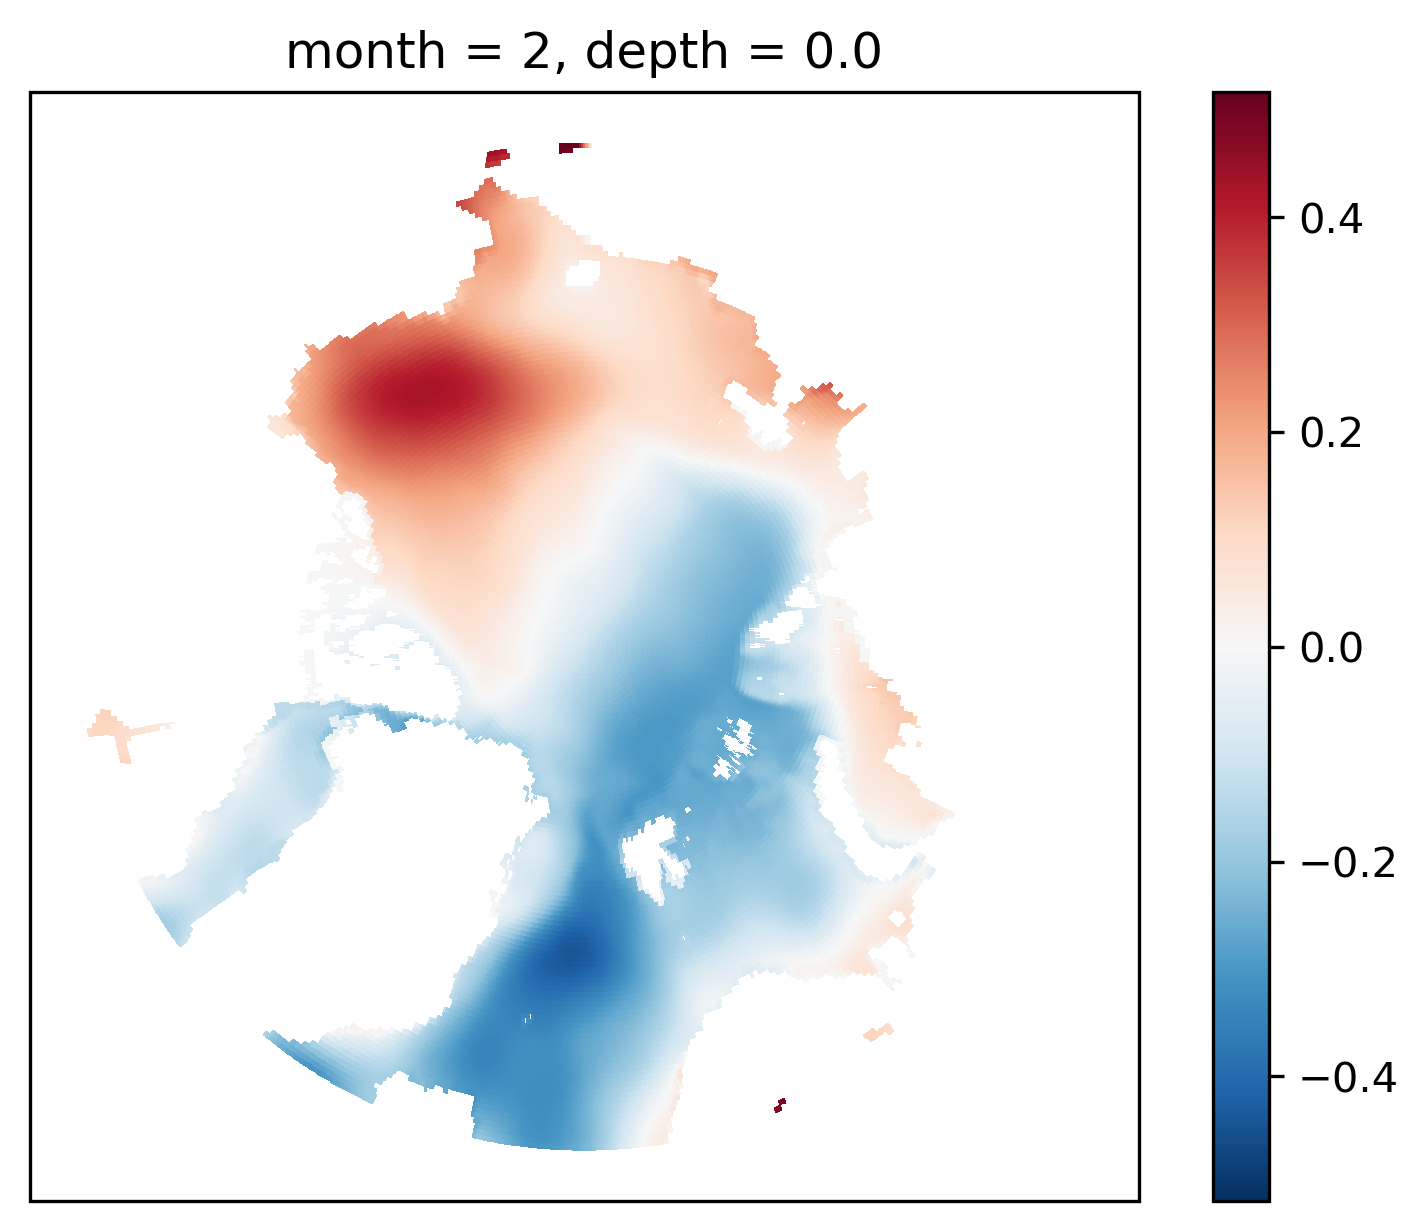

In [121]:
# 4. Fixing the Datetime line hole
# there is a whole around the dateline
# We identify the hole
bad_lon_idx = [-3,-2, -1, 0, 1,2]         # dateline gap
lat_min, lat_max = 65, 90

# Create a mask
bad_lons = ds.lon.isel(lon=bad_lon_idx)
badmask = ((ds.lat >= lat_min) & (ds.lat <= lat_max) & ds.lon.isin(bad_lons))
# badmask.plot(alpha=.5, transform=ccrs.PlateCarree())


# Replace the fake zeros in the mask with NaN
SSH2 = SSH.where(~badmask, np.nan)

# To take care of periodicity we need to roll the entire array and interpolate and then roll back
SSH2=SSH2.roll({'lon': 6})

# # Now linearly interpolate only along longitude
SSH_interp = SSH2.interpolate_na(#scipy.interpolate.interp1d(
    dim='lon',
    method="linear",
    fill_value="extrapolate",
    # period=True
)

# roll back
SSH_interp_rerolled=SSH_interp.roll({'lon':-6})

# Path the hole
SSH= xr.where(badmask,SSH_interp_rerolled,SSH)

# The values on land are still zeroes, we replace those by np.nan
SSH= xr.where(SSH==0,np.nan,SSH)

fig,ax = plt.subplots(subplot_kw={'projection' : ccrs.NorthPolarStereo()}, dpi=300)
SSH.isel(month=1).plot(transform=ccrs.PlateCarree())


In [106]:
SSH.lat

<xarray.DataArray 'lat' (lat: 101)> Size: 404B
array([65.  , 65.25, 65.5 , 65.75, 66.  , 66.25, 66.5 , 66.75, 67.  , 67.25,
       67.5 , 67.75, 68.  , 68.25, 68.5 , 68.75, 69.  , 69.25, 69.5 , 69.75,
       70.  , 70.25, 70.5 , 70.75, 71.  , 71.25, 71.5 , 71.75, 72.  , 72.25,
       72.5 , 72.75, 73.  , 73.25, 73.5 , 73.75, 74.  , 74.25, 74.5 , 74.75,
       75.  , 75.25, 75.5 , 75.75, 76.  , 76.25, 76.5 , 76.75, 77.  , 77.25,
       77.5 , 77.75, 78.  , 78.25, 78.5 , 78.75, 79.  , 79.25, 79.5 , 79.75,
       80.  , 80.25, 80.5 , 80.75, 81.  , 81.25, 81.5 , 81.75, 82.  , 82.25,
       82.5 , 82.75, 83.  , 83.25, 83.5 , 83.75, 84.  , 84.25, 84.5 , 84.75,
       85.  , 85.25, 85.5 , 85.75, 86.  , 86.25, 86.5 , 86.75, 87.  , 87.25,
       87.5 , 87.75, 88.  , 88.25, 88.5 , 88.75, 89.  , 89.25, 89.5 , 89.75,
       90.  ], dtype=float32)
Coordinates:
  * lat      (lat) float32 404B 65.0 65.25 65.5 65.75 ... 89.25 89.5 89.75 90.0
    depth    float32 4B 0.0

In [ ]:
# we pad the SSH with the same values such that the gradients vanish at the coast 
# WOW No slip
lim=10
SSH_lon=SSH.interpolate_na(dim='lon',method='nearest',limit=lim)
SSH_lat=SSH.interpolate_na(dim='lat',method='nearest',limit=lim)

fig,ax=plt.subplots(subplot_kw={'projection' : ccrs.NorthPolarStereo()},dpi=300)
SSH_lon.isel(month=10).plot(transform=ccrs.PlateCarree(),cmap='viridis')
# land.plot(transform=ccrs.PlateCarree())

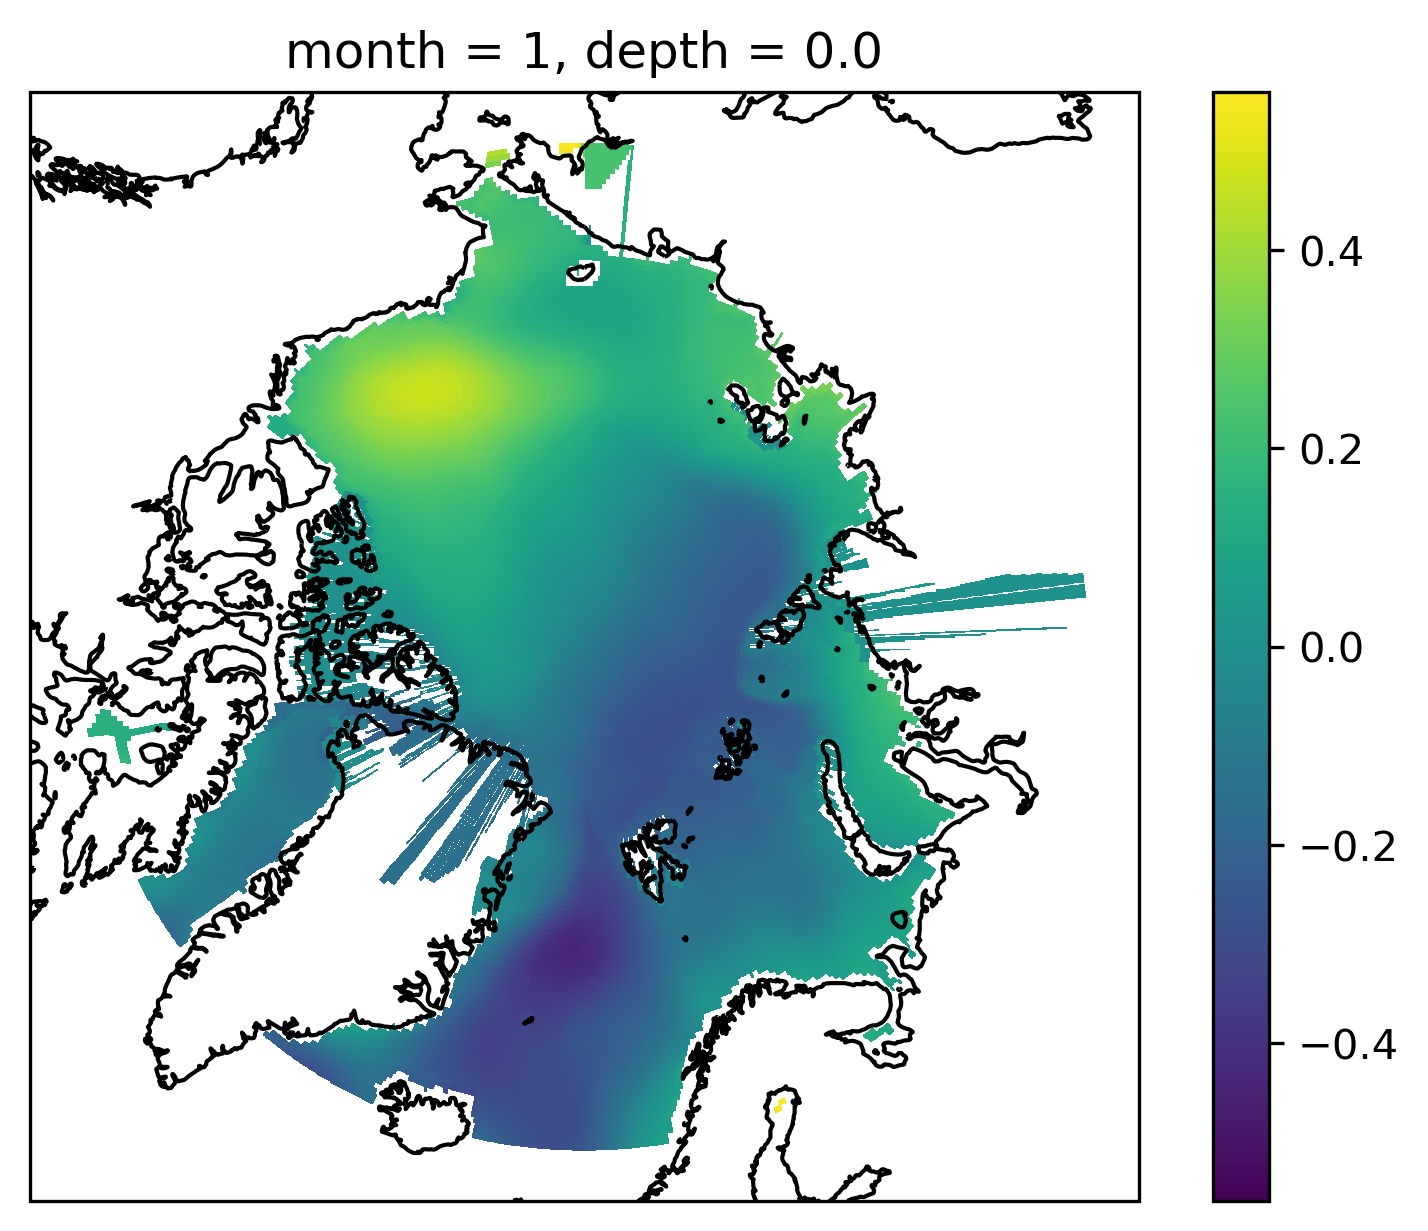

In [ ]:

# # idx = scipy.ndimage.distance_transform_edt(land, return_indices=True, return_distances=False)
# # filled=  SSH.copy(data=SSH.values[idx[0], idx[1]])
# # fig,ax=plt.subplots(subplot_kw={'projection' : ccrs.NorthPolarStereo()},dpi=300)

# #sHH=shh.interpolate_na(dim='lat',method='nearest',limit=20)
# # shh=xr.where(np.isnan(ds["Temp"].isel({"depth":0})), np.nan, shh)

# fig,ax=plt.subplots(subplot_kw={'projection' : ccrs.NorthPolarStereo()},dpi=300)
# filled.isel(month=0).plot(transform=ccrs.PlateCarree(),cmap='viridis')
# ax.coastlines()

In [ ]:
# compute thee derivatives on the padded array for vanishing gradients
dx = 9.8 * SSH_lon.differentiate("lon")/x_scale
dy = 9.8 * SSH_lat.differentiate("lat")/y_scale
u= -dy/f
v= dx/f
speednan = np.isnan(u*v)

# ensure to remove the u/v values that are in zones where the opposite components is nan
# i.e. some padded regions have 0 (no gradient) but are not nan none the less
u= xr.where(speednan, np.nan, u)
v= xr.where(speednan, np.nan, v)

# we now want to make the land 0 again such that we can interpolate between last non-zero and the coast where it is truly zero

# u_intrp= xr.where(land,0,u)
# v_intrp= xr.where(land,0,v)

# u = u_intrp.interpolate_na(
#     dim="lon",
#     method="cubic",
#     #limit=50
#     fill_value="extrapolate"
# )
# v = v_intrp.interpolate_na(
#     dim="lat",
#     method="cubic",
#     #limit=50
#     fill_value="extrapolate"
# )

# speed=xr.where(land,0,np.sqrt(u**2+v**2))

In [ ]:
# blurring
BLUR_RADIUS_CELLS=3
ds=ds.sel(lat=slice(65,89))
u,v =u.sel(lat=slice(65,89)),v.sel(lat=slice(65,89))
u_blurred = scipy.ndimage.gaussian_filter(u, sigma=BLUR_RADIUS_CELLS, axes=(1,1))
ds['u']=(['lat','lon'],u_blurred)

v_blurred = scipy.ndimage.gaussian_filter(v, sigma=BLUR_RADIUS_CELLS)
ds['v']=(['lat','lon'],v_blurred)

ds['speed']=(ds['u']**2+ds['v']**2)**.5